I denna notebook rensar vi data från onlinesessionen för både Stroop och Flankeer. Utgångspunkten är de filer som innehåller varje deltagares onlinesession. För att kunna redovisa hur mycket data som sorteras bort för vi en logg som registrerar antal deltagare och trials efter varje steg. 

In [1]:
# Läs in filerna med onlinesessionerna och starta loggen
import pandas as pd

stroop  = pd.read_csv("stroop_online.csv")
flanker = pd.read_csv("flanker_online.csv")

logg = []   # skapar en rensningslogg i form av en tom lista där varje rensningsteg läggs till.  
def logga(steg): # funktion som lägger till en rad i rensningsloggen.
    logg.append({"Steg": steg,
                 "Deltagare": stroop["subjectid"].nunique(), #räknar antalet unika deltagare i Stroop
                 "Deltagare Flanker": flanker["subjectid"].nunique(), #räknar antalet unika deltagare i Flanker
                 "Stroop trials": len(stroop), #räknar antalet trials
                 "Flanker trials": len(flanker)})

logga("Onlinesession") #sparar utgångslägget innan rensning gjorts. 

In [2]:
pd.DataFrame(logg)

,Steg,Deltagare,Deltagare Flanker,Stroop trials,Flanker trials
0,Onlinesession,461,460,64540,64860


In [3]:
# kontrollerar vilka ID som finns i en av uppgifterna. 
bara_stroop  = set(stroop["subjectid"]) - set(flanker["subjectid"])
bara_flanker = set(flanker["subjectid"]) - set(stroop["subjectid"])
print("Bara Stroop:", sorted(bara_stroop))      # [217]
print("Bara Flanker:", sorted(bara_flanker))    # []

Bara Stroop: [217]
Bara Flanker: []


In [4]:
# Behåll personer med båda uppgifterna. 
båda = set(stroop["subjectid"]) & set(flanker["subjectid"]) # hitta gemensamma deltagare
stroop  = stroop[stroop["subjectid"].isin(båda)] #filtrera båda tabellerna för att behålla gemensamma ID
flanker = flanker[flanker["subjectid"].isin(båda)]
logga("Båda uppgifterna") # lägger till en rad i loggen         )

Deltagare som enbart gar
Motivering:
Vår analys bygger på att varje deltagare har data från båda uppgifterna, eftersom vi jämför Stroop och Flanker effekten inom samma person. Vi behöll därmed bara delatagare som hade en onlinesession i båda uppgifterna. Deltagare med ID 217 hade Stroop data men saknade Flanker och exkluderades därmed. Därefter återstår 460 deltagare.  

In [5]:
# Exkludera personer med låg andel rätt
acc_stroop  = stroop.groupby("subjectid")["correct"].mean()
acc_flanker = flanker.groupby("subjectid")["correct"].mean()

låg = acc_stroop[acc_stroop < 0.80].index.union(acc_flanker[acc_flanker < 0.80].index) # behåller enbart deltagare under 80 % i Stroop ELLER Flanker. 
print("Exkluderas:", list(låg))

stroop  = stroop[~stroop["subjectid"].isin(låg)]
flanker = flanker[~flanker["subjectid"].isin(låg)]
logga("Andel rätt ≥ 80 %")       # 452 deltagare

Exkluderas: [6, 42, 45, 84, 162, 168, 173, 239]


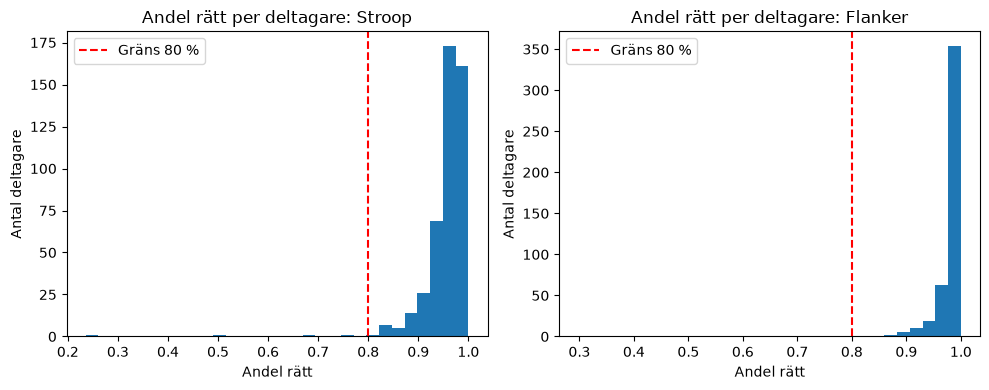

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, acc, namn in [(axes[0], acc_stroop, "Stroop"), (axes[1], acc_flanker, "Flanker")]:
    ax.hist(acc, bins=30)
    ax.axvline(0.80, color="red", linestyle="--", label="Gräns 80 %")
    ax.set_title(f"Andel rätt per deltagare: {namn}")
    ax.set_xlabel("Andel rätt")
    ax.set_ylabel("Antal deltagare")
    ax.legend()
plt.tight_layout()
plt.show()

Deltagare med mindre än 80 % rätt svar exkluderades. 
Motivering:
Låg andel rätt kan tyder på att något har gått fel under onlinemätningen: Det kan vara deltagare som inte förstått instruktion, varit distraherad eller inte ansträngt sig. Risken för detta är extra stor då datainsamlingen skedde online utan någon försöksledare på plats. Gränsen ligger långt över slumpnivån (25 % för Stroop med fyra svarsalternativ och 50 % i flanker med två) och långt under genomsnittet (ca 96 % flr Stroop och 98 % för Flanker.). Histogram över andelen rätt visar att de flesta ligger över genomsnittet medan ett fåtal avviker. Åtta deltagare exkluderas och valet av gräns påverkar därmed relativt få.


In [7]:
# Felandel per villkor, sedan bort med felsvar
print(1 - stroop.groupby("values.congruency")["correct"].mean())    # felandel Stroop
print(1 - flanker.groupby("values.congruence")["correct"].mean())   # felandel Flanker

stroop  = stroop[stroop["correct"] == 1]
flanker = flanker[flanker["correct"] == 1]
logga("Bara korrekta svar")

values.congruency
1    0.026755
2    0.055151
Name: correct, dtype: float64
values.congruence
1    0.005811
2    0.027870
Name: correct, dtype: float64


In [8]:
# Ta bort extremvärden i RT
stroop  = stroop[(stroop["latency"] >= 200) & (stroop["latency"] <= 3000)]
flanker = flanker[flanker["latency"] >= 200]
logga("RT-gränser")

In [9]:
# Kontrollera att det finns tillräckligt med data per person
print(stroop.groupby(["subjectid", "values.congruency"]).size().min())    # minst cirka 40
print(flanker.groupby(["subjectid", "values.congruence"]).size().min())   # minst cirka 48

40
48


In [10]:
# Visa loggen och spara
display(pd.DataFrame(logg))

stroop.to_csv("stroop_rensad.csv", index=False)
flanker.to_csv("flanker_rensad.csv", index=False)

,Steg,Deltagare,Deltagare Flanker,Stroop trials,Flanker trials
0,Onlinesession,461,460,64540,64860
1,Båda uppgifterna,460,460,64400,64860
2,Andel rätt ≥ 80 %,452,452,63280,63732
3,Bara korrekta svar,452,452,60689,62658
4,RT-gränser,452,452,60217,62639
